## 1. Khởi tạo Spark

In [1]:
import os, sys

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
# Spark trên Windows cần hadoop.dll trong PATH để ghi file
os.environ["PATH"] = os.path.join(os.environ.get("HADOOP_HOME", r"C:\hadoop"), "bin") + os.pathsep + os.environ["PATH"]

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import (StructType, StructField, IntegerType, LongType,
                               DoubleType, StringType)

# Cho phép import các module .py ở thư mục gốc project
sys.path.insert(0, os.path.abspath(".."))
from geo_utils import haversine_km

spark = (SparkSession.builder
         .master("local[*]")
         .appName("RussiaRealEstate")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
spark.version

'3.5.3'

## 2. Đọc dữ liệu

In [2]:
schema = StructType([
    StructField("price",         LongType()),
    StructField("date",          StringType()),
    StructField("time",          StringType()),
    StructField("geo_lat",       DoubleType()),
    StructField("geo_lon",       DoubleType()),
    StructField("region",        IntegerType()),
    StructField("building_type", IntegerType()),
    StructField("level",         IntegerType()),
    StructField("levels",        IntegerType()),
    StructField("rooms",         IntegerType()),
    StructField("area",          DoubleType()),
    StructField("kitchen_area",  DoubleType()),
    StructField("object_type",   IntegerType()),
])

DATA_PATH = "../data/raw/russia-real-estate.csv"
df = spark.read.csv(DATA_PATH, header=True, schema=schema)
df.printSchema()

root
 |-- price: long (nullable = true)
 |-- date: string (nullable = true)
 |-- time: string (nullable = true)
 |-- geo_lat: double (nullable = true)
 |-- geo_lon: double (nullable = true)
 |-- region: integer (nullable = true)
 |-- building_type: integer (nullable = true)
 |-- level: integer (nullable = true)
 |-- levels: integer (nullable = true)
 |-- rooms: integer (nullable = true)
 |-- area: double (nullable = true)
 |-- kitchen_area: double (nullable = true)
 |-- object_type: integer (nullable = true)



In [3]:
df.show(10)

+-------+----------+--------+----------+----------+------+-------------+-----+------+-----+----+------------+-----------+
|  price|      date|    time|   geo_lat|   geo_lon|region|building_type|level|levels|rooms|area|kitchen_area|object_type|
+-------+----------+--------+----------+----------+------+-------------+-----+------+-----+----+------------+-----------+
|6050000|2018-02-19|20:00:21|59.8058084| 30.376141|  2661|            1|    8|    10|    3|82.6|        10.8|          1|
|8650000|2018-02-27|12:04:54| 55.683807| 37.297405|    81|            3|    5|    24|    2|69.1|        12.0|          1|
|4000000|2018-02-28|15:44:00|  56.29525| 44.061637|  2871|            1|    5|     9|    3|66.0|        10.0|          1|
|1850000|2018-03-01|11:24:52| 44.996132| 39.074783|  2843|            4|   12|    16|    2|38.0|         5.0|         11|
|5450000|2018-03-01|17:42:43| 55.918767| 37.984642|    81|            3|   13|    14|    2|60.0|        10.0|          1|
|3300000|2018-03-02|21:1

In [4]:
print(f"Số dòng: {df.count():,}")
print(f"Số cột: {len(df.columns)}")
print(f"Số phân vùng: {df.rdd.getNumPartitions()}")

Số dòng: 5,477,006
Số cột: 13
Số phân vùng: 8


## 3. Kiểm tra chất lượng dữ liệu

Số dòng trùng hoàn toàn trên cả 13 cột.

In [5]:
n_total = df.count()
n_distinct = df.dropDuplicates().count()
n_dup = n_total - n_distinct
print(f"Số dòng trùng hoàn toàn: {n_dup:,} ({n_dup / n_total:.4%})")

Số dòng trùng hoàn toàn: 1,523 (0.0278%)


Tỷ lệ giá trị thiếu (null hoặc NaN) của từng cột.

In [6]:
dbl_cols = {f.name for f in df.schema.fields if f.dataType.typeName() == "double"}
is_missing = lambda c: F.col(c).isNull() | (F.isnan(c) if c in dbl_cols else F.lit(False))

counts = df.select(F.count("*").alias("n_total"),
                   *[F.sum(is_missing(c).cast("int")).alias(c) for c in df.columns])

missing = (counts
    .select("n_total", F.explode(F.array(*[
        F.struct(F.lit(c).alias("column"), F.col(c).alias("n_missing")) for c in df.columns
    ])).alias("m"))
    .select("m.column", "m.n_missing",
            F.round(100 * F.col("m.n_missing") / F.col("n_total"), 4).alias("pct_missing")))
missing.show(len(df.columns), truncate=False)

+-------------+---------+-----------+
|column       |n_missing|pct_missing|
+-------------+---------+-----------+
|price        |0        |0.0        |
|date         |0        |0.0        |
|time         |0        |0.0        |
|geo_lat      |0        |0.0        |
|geo_lon      |0        |0.0        |
|region       |0        |0.0        |
|building_type|0        |0.0        |
|level        |0        |0.0        |
|levels       |0        |0.0        |
|rooms        |0        |0.0        |
|area         |0        |0.0        |
|kitchen_area |0        |0.0        |
|object_type  |0        |0.0        |
+-------------+---------+-----------+



Thống kê mô tả sơ bộ các cột số của bộ dữ liệu.

In [7]:
df.select("price", "area", "kitchen_area", "rooms", "level", "levels").summary().show()

+-------+--------------------+-----------------+------------------+------------------+------------------+------------------+
|summary|               price|             area|      kitchen_area|             rooms|             level|            levels|
+-------+--------------------+-----------------+------------------+------------------+------------------+------------------+
|  count|             5477006|          5477006|           5477006|           5477006|           5477006|           5477006|
|   mean|   4422029.022870342| 53.9182485540514|10.628397451086638|1.7261733874310161| 6.214529982256729|11.398920322526578|
| stddev|2.1507519154801387E7|33.35292599831139| 9.792379874595767|1.0821327377639443|4.9574192770725585| 6.535733868398391|
|    min|         -2144967296|             0.07|              0.01|                -2|                 1|                 1|
|    25%|             1950000|             38.0|               7.0|                 1|                 2|                 5|


Khoảng thời gian thu thập dữ liệu và phạm vi tọa độ.

In [8]:
r = df.select(
    F.min(F.to_date("date")).alias("min_day"), F.max(F.to_date("date")).alias("max_day"),
    F.min("geo_lat").alias("min_lat"),         F.max("geo_lat").alias("max_lat"),
    F.min("geo_lon").alias("min_lon"),         F.max("geo_lon").alias("max_lon"),
).first()

print(f"Khoảng thời gian thu thập: {r.min_day} đến {r.max_day} ({(r.max_day - r.min_day).days + 1:,} ngày)")
print(f"Latitude:  {r.min_lat} đến {r.max_lat}")
print(f"Longitude: {r.min_lon} đến {r.max_lon}")

Khoảng thời gian thu thập: 2018-02-19 đến 2021-05-01 (1,168 ngày)
Latitude:  41.4590611 đến 71.9803994
Longitude: 19.890196 đến 162.5360775


Số bản ghi có giá không hợp lệ (`price <= 0`).

In [9]:
n_total = df.count()
n_bad_price = df.filter(F.col("price") <= 0).count()
print(f"Số bản ghi có price <= 0: {n_bad_price:,} ({n_bad_price / n_total:.4%})")

Số bản ghi có price <= 0: 388 (0.0071%)


Số bản ghi có `rooms` bằng 0, -1 (studio) hoặc -2 (không mô tả).

In [10]:
(df.filter(F.col("rooms").isin(0, -1, -2))
   .groupBy("rooms").count()
   .orderBy("rooms")
   .show())

+-----+------+
|rooms| count|
+-----+------+
|   -2|   343|
|   -1|306209|
+-----+------+



Kiểm tra mâu thuẫn logic: tầng căn hộ cao hơn tổng số tầng, diện tích bếp lớn hơn tổng diện tích.

In [11]:
n_total = df.count()
n_level = df.filter(F.col("level") > F.col("levels")).count()
n_kitchen = df.filter(F.col("kitchen_area") > F.col("area")).count()
print(f"Số dòng có level > levels: {n_level:,} ({n_level / n_total:.4%})")
print(f"Số dòng có kitchen_area > area: {n_kitchen:,} ({n_kitchen / n_total:.4%})")

Số dòng có level > levels: 1,072 (0.0196%)
Số dòng có kitchen_area > area: 3,266 (0.0596%)


Bản đồ phân bố bản ghi

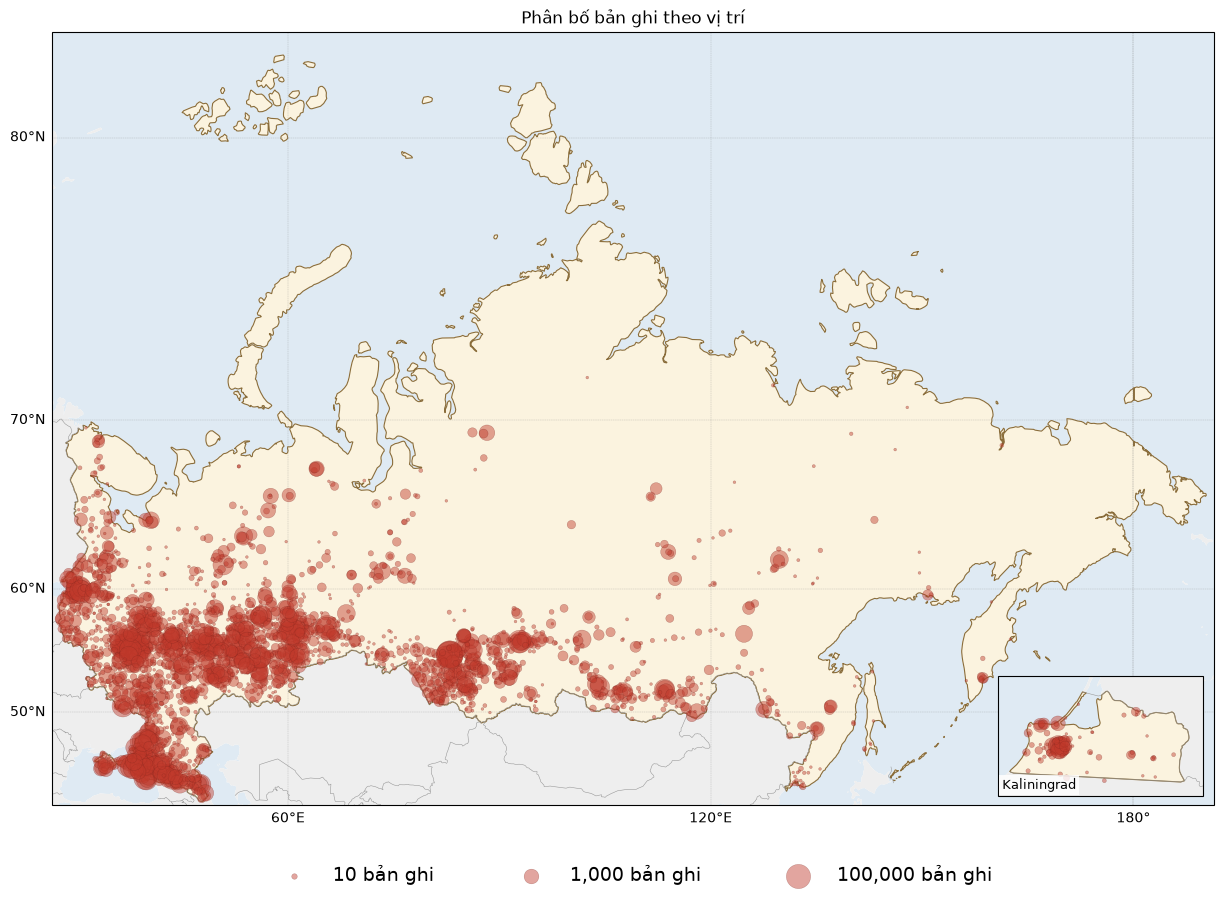

In [12]:
import numpy as np
import shapely
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader

def grid_counts(data, grid):
    """Gộp bản ghi theo lưới `grid` độ ngay trong Spark; mỗi ô đặt tại tọa độ trung bình của các bản ghi trong ô."""
    return (data.groupBy(F.floor(F.col("geo_lat") / grid).alias("gy"),
                         F.floor(F.col("geo_lon") / grid).alias("gx"))
                .agg(F.count("*").alias("n"),
                     F.avg("geo_lat").alias("lat"),
                     F.avg("geo_lon").alias("lon"))
                .toPandas())

KGD_BOX = [19.4, 23.1, 54.2, 55.45]   # lon_min, lon_max, lat_min, lat_max của Kaliningrad
cells = grid_counts(df, 0.5)
cells_kgd = grid_counts(df.filter(F.col("geo_lon").between(*KGD_BOX[:2]) &
                                  F.col("geo_lat").between(*KGD_BOX[2:])), 0.05)

LON0 = 109   # kinh tuyến giữa, để Chukotka (vượt qua kinh tuyến 180°) không bị cắt
pc, pc0 = ccrs.PlateCarree(), ccrs.PlateCarree(central_longitude=LON0)
size = lambda n: 4 + 12 * np.log10(n) ** 2
bubble = dict(color="#c0392b", alpha=0.45, edgecolor="#7b241c", linewidth=0.3, zorder=2)

def draw_base(ax, scale):
    countries = shapereader.Reader(shapereader.natural_earth(scale, "cultural", "admin_0_countries"))
    # Dời kinh độ về hệ có kinh tuyến giữa LON0 rồi gộp, để hai mảnh Chukotka ở hai bên kinh tuyến 180° liền làm một
    russia = shapely.union_all([
        shapely.transform(c.geometry, lambda xy: np.c_[(xy[:, 0] - LON0 + 180) % 360 - 180, xy[:, 1]])
        for c in countries.records() if c.attributes["ADM0_A3"] == "RUS"])
    ax.add_feature(cfeature.OCEAN.with_scale(scale), facecolor="#dfeaf3", zorder=0)
    ax.add_feature(cfeature.LAND.with_scale(scale), facecolor="#eeeeee", zorder=0)
    ax.add_geometries([russia], crs=pc0, facecolor="#fbf3df", edgecolor="#8a6d3b", linewidth=0.8, zorder=1)
    ax.add_feature(cfeature.BORDERS.with_scale(scale), linewidth=0.4, edgecolor="#999999", zorder=1)

# Bản đồ chính: Mercator, bao trọn lãnh thổ Nga trừ Kaliningrad (vẽ ở khung riêng)
fig, ax = plt.subplots(figsize=(15, 11),
                       subplot_kw={"projection": ccrs.Mercator(central_longitude=LON0)})
ax.set_extent([-82.5, 82.5, 40.8, 82.3], crs=pc0)
draw_base(ax, "50m")
gl = ax.gridlines(crs=pc, draw_labels=True, linewidth=0.3, color="gray", alpha=0.5, linestyle="--")
gl.top_labels = gl.right_labels = False
ax.scatter(cells["lon"], cells["lat"], s=size(cells["n"]), transform=pc, **bubble)

# Kaliningrad: khung phóng to ở góc dưới bên phải (vùng biển trống, không che lãnh thổ)
axk = ax.inset_axes([0.812, 0.012, 0.18, 0.155], projection=ccrs.Mercator())
axk.set_extent(KGD_BOX, crs=pc)
draw_base(axk, "10m")
axk.scatter(cells_kgd["lon"], cells_kgd["lat"], s=size(cells_kgd["n"]), transform=pc, **bubble)
axk.text(0.02, 0.03, "Kaliningrad", transform=axk.transAxes, fontsize=9,
         ha="left", va="bottom", bbox=dict(facecolor="white", alpha=0.8, edgecolor="none", pad=2))

for n in (10, 1_000, 100_000):
    ax.scatter([], [], s=size(n), label=f"{n:,} bản ghi", **bubble)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.04), ncol=3, frameon=False,
          fontsize=14, columnspacing=4, handletextpad=1, borderpad=1)
ax.set_title("Phân bố bản ghi theo vị trí")
plt.show()

Top 10 tọa độ có nhiều bản ghi nhất.

In [13]:
(df.groupBy("geo_lat", "geo_lon", "region")
   .agg(F.count("*").alias("n_records"))
   .orderBy(F.desc("n_records"))
   .show(10, truncate=False))

+----------+----------+------+---------+
|geo_lat   |geo_lon   |region|n_records|
+----------+----------+------+---------+
|55.0303931|83.0155452|9654  |106177   |
|55.014108 |83.0016615|9654  |29577    |
|55.0128684|82.9999987|9654  |26030    |
|54.9471407|82.9585961|9654  |21055    |
|59.939084 |30.315879 |2661  |20873    |
|55.017756 |83.003578 |9654  |18885    |
|55.0176723|83.003522 |9654  |17999    |
|55.0139939|83.0033194|9654  |16518    |
|55.0128402|83.0018862|9654  |15983    |
|55.7943584|49.1114975|2922  |13626    |
+----------+----------+------+---------+
only showing top 10 rows



## 4. Làm sạch và bổ sung cột

Loại bản ghi trùng hoàn toàn (trước khi bỏ cột `time`) và các bản ghi sai logic; in số bản ghi bị loại ở từng bước.

In [14]:
clean = df.dropDuplicates().cache()
n_raw, n = df.count(), clean.count()
print(f"{'Trùng hoàn toàn':<22} loại {n_raw - n:>6,} bản ghi")

keep_rules = {
    "price <= 0":          F.col("price") > 0,
    "rooms = -2":          F.col("rooms") != -2,
    "level > levels":      F.col("level") <= F.col("levels"),
    "kitchen_area > area": F.col("kitchen_area") <= F.col("area"),
}
for name, keep in keep_rules.items():
    n_prev, clean = n, clean.filter(keep)
    n = clean.count()
    print(f"{name:<22} loại {n_prev - n:>6,} bản ghi")
print(f"Còn lại: {n:,} / {n_raw:,} bản ghi ({n / n_raw:.2%})")

Trùng hoàn toàn        loại  1,523 bản ghi


price <= 0             loại    388 bản ghi


rooms = -2             loại    343 bản ghi


level > levels         loại  1,072 bản ghi


kitchen_area > area    loại  3,139 bản ghi
Còn lại: 5,470,541 / 5,477,006 bản ghi (99.88%)


Đổi `object_type` thành `pre_owned_house` (1: nhà đã qua sử dụng, 0: nhà mới), bỏ cột `time`, thêm `is_studio` và đổi `rooms` của studio từ -1 về 0.

In [15]:
clean = (clean
    .withColumn("pre_owned_house", (F.col("object_type") == 1).cast("int"))
    .withColumn("is_studio", (F.col("rooms") == -1).cast("int"))
    .withColumn("rooms", F.when(F.col("rooms") == -1, 0).otherwise(F.col("rooms")))
    .drop("object_type", "time"))

Chuyển `building_type` từ mã số sang nhãn phân loại.

In [16]:
BUILDING_TYPES = {0: "Others", 1: "Panel", 2: "Monolithic", 3: "Brick", 4: "Block", 5: "Wooden"}
bt_map = F.create_map(*[F.lit(x) for kv in BUILDING_TYPES.items() for x in kv])
clean = clean.withColumn("building_type", bt_map[F.col("building_type")])
clean.groupBy("building_type").count().orderBy(F.desc("count")).show()

+-------------+-------+
|building_type|  count|
+-------------+-------+
|        Panel|1953360|
|        Brick|1890040|
|   Monolithic|1129698|
|       Others| 306929|
|        Block| 174215|
|       Wooden|  16299|
+-------------+-------+



Thêm tên vùng (chủ thể liên bang) `province` và tọa độ thủ phủ của vùng từ `data/raw/region_names.csv` (tạo bởi `region_lookup.py`).

In [17]:
regions = (spark.read.csv("../data/raw/region_names.csv", header=True, inferSchema=True)
           .withColumn("center", F.split("capital_coord", ", "))
           .select("region", "province",
                   F.col("center")[0].cast("double").alias("center_lat"),
                   F.col("center")[1].cast("double").alias("center_lon")))
clean = clean.join(F.broadcast(regions), on="region", how="left")

Khoảng cách (km) từ mỗi bản ghi tới thủ phủ của vùng, theo công thức haversine (khoảng cách trên mặt cầu bán kính 6.371 km, hàm `haversine_km` trong `geo_utils.py`).

In [18]:
clean = (clean.withColumn("distance_to_capital", haversine_km(F.col("geo_lat"), F.col("geo_lon"),
                                                               F.col("center_lat"), F.col("center_lon")))
              .drop("center_lat", "center_lon"))

Sắp xếp lại thứ tự cột, kiểm tra giá trị thiếu sau khi ghép và xem kết quả.

In [19]:
clean = clean.select("price", "date", "geo_lat", "geo_lon", "region", "province",
                     "distance_to_capital", "building_type", "pre_owned_house",
                     "level", "levels", "rooms", "is_studio", "area", "kitchen_area")
print("Bản ghi thiếu province:", clean.filter(F.col("province").isNull()).count())
print("Bản ghi thiếu building_type:", clean.filter(F.col("building_type").isNull()).count())
clean.printSchema()
clean.show(5, truncate=False)

Bản ghi thiếu province: 0


Bản ghi thiếu building_type: 0
root
 |-- price: long (nullable = true)
 |-- date: string (nullable = true)
 |-- geo_lat: double (nullable = true)
 |-- geo_lon: double (nullable = true)
 |-- region: integer (nullable = true)
 |-- province: string (nullable = true)
 |-- distance_to_capital: double (nullable = true)
 |-- building_type: string (nullable = true)
 |-- pre_owned_house: integer (nullable = true)
 |-- level: integer (nullable = true)
 |-- levels: integer (nullable = true)
 |-- rooms: integer (nullable = true)
 |-- is_studio: integer (nullable = true)
 |-- area: double (nullable = true)
 |-- kitchen_area: double (nullable = true)



+-------+----------+----------+----------+------+----------------+-------------------+-------------+---------------+-----+------+-----+---------+----+------------+
|price  |date      |geo_lat   |geo_lon   |region|province        |distance_to_capital|building_type|pre_owned_house|level|levels|rooms|is_studio|area|kitchen_area|
+-------+----------+----------+----------+------+----------------+-------------------+-------------+---------------+-----+------+-----+---------+----+------------+
|6050000|2018-02-19|59.8058084|30.376141 |2661  |Saint Petersburg|15.120712005815285 |Panel        |1              |8    |10    |3    |0        |82.6|10.8        |
|4704280|2018-03-04|55.6210965|37.4310016|3     |Moscow          |19.013601988136667 |Monolithic   |0              |1    |25    |1    |0        |31.7|6.0         |
|2800000|2018-03-06|55.7369718|38.8464565|81    |Moscow Oblast   |76.92668434512137  |Panel        |1              |9    |10    |2    |0        |55.0|8.0         |
|2220000|2018-04

Lưu dữ liệu đã làm sạch ra `data/clean.parquet`.

In [20]:
CLEAN_PATH = "../data/clean.parquet"
clean.write.mode("overwrite").parquet(CLEAN_PATH)
print(f"Đã lưu {spark.read.parquet(CLEAN_PATH).count():,} bản ghi vào {CLEAN_PATH}")

Đã lưu 5,470,541 bản ghi vào ../data/clean.parquet
